In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# read the raw data
df = pd.read_csv("Electric_Vehicle_Population_Data.csv")

df.sample(5)

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
18967,1N4BZ1BV7N,King,Renton,WA,98059,2022,NISSAN,LEAF,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,11.0,192804797,POINT (-122.15771 47.50549),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53033025103
60311,5YJ3E1EBXK,King,Seattle,WA,98109,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220,0,36.0,217548075,POINT (-122.346385 47.630685),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),53033006800
25715,WBY1Z8C31H,Pierce,Edgewood,WA,98372,2017,BMW,I3,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,97,0,31.0,107151075,POINT (-122.28556 47.18709),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53053073502
34710,5YJ3E1EB4J,King,Snoqualmie,WA,98065,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,5.0,291050133,POINT (-121.82432 47.52716),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA),53033032603
38665,5YJ3E1EA2J,Snohomish,Bothell,WA,98021,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,1.0,122102774,POINT (-122.18384 47.8031),PUGET SOUND ENERGY INC,53061051918


In [2]:
# drop nas and dups
ev_df = df.dropna().copy()
ev_df = ev_df.drop_duplicates()
print(f"dropped {len(df) - len(ev_df)} bad rows initially")

# keep only realistic range & price (no zeros)
valid_mask = (ev_df["Electric Range"] > 0) & (ev_df['Base MSRP'] > 0)
valid_evs = ev_df.loc[valid_mask].copy()

# IQR filtering for range
q1 = valid_evs['Electric Range'].quantile(0.25)
q3 = valid_evs["Electric Range"].quantile(0.75)
iqr_val = q3-q1

lower_limit = q1 - (1.5*iqr_val)
upper_limit = q3 + (1.5*iqr_val)

# apply bounds
outlier_mask = (valid_evs['Electric Range'] >= lower_limit) & (valid_evs["Electric Range"] <= upper_limit)
df_final = valid_evs.loc[outlier_mask].copy()

print(f"clean data size: {len(df_final)}")

dropped 482 bad rows initially
clean data size: 3498


In [3]:
# stats overview
display(ev_df.describe())
display(ev_df.describe(include='object'))

# check ev type proportions
ev_share = ev_df["Electric Vehicle Type"].value_counts(normalize=True)*100
print("ev type breakdown (%):\n", ev_share.round(2))

,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,112152.000000,112152.000000,112152.000000,112152.000000,112152.000000,1.121520e+05,1.121520e+05
mean,98258.856659,2019.004494,87.829651,1793.882320,29.817703,1.994712e+08,5.303958e+10
std,302.889935,2.891859,102.336645,10785.259118,14.698726,9.401842e+07,1.617788e+07
min,98001.000000,1997.000000,0.000000,0.000000,1.000000,4.777000e+03,5.300195e+10
25%,98052.000000,2017.000000,0.000000,0.000000,18.000000,1.484164e+08,5.303301e+10
50%,98121.000000,2020.000000,32.000000,0.000000,34.000000,1.923916e+08,5.303303e+10
75%,98370.000000,2022.000000,208.000000,0.000000,43.000000,2.191885e+08,5.305307e+10
max,99403.000000,2023.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.307794e+10


,VIN (1-10),County,City,State,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Vehicle Location,Electric Utility
count,112152,112152,112152,112152,112152,112152,112152,112152,112152,112152
unique,7522,39,435,1,34,114,2,3,516,73
top,5YJYGDEE9M,King,Seattle,WA,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,POINT (-122.13158 47.67858),PUGET SOUND ENERGY INC||CITY OF TACOMA - (WA)
freq,471,58980,20295,112152,51883,23042,85732,58395,2914,40231


ev type breakdown (%):
 Electric Vehicle Type
Battery Electric Vehicle (BEV)            76.44
Plug-in Hybrid Electric Vehicle (PHEV)    23.56
Name: proportion, dtype: float64


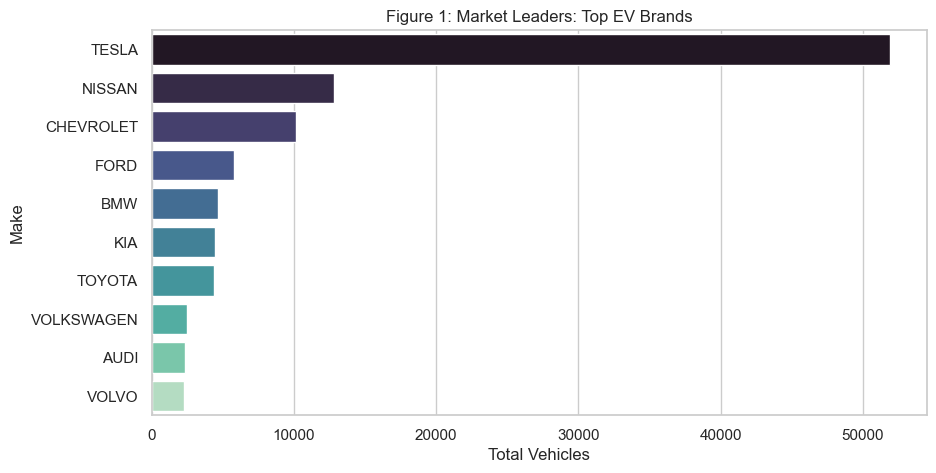

In [5]:
# plot top 10 makes
sns.set_theme(style='whitegrid')
plt.figure(figsize=(10, 5))

top_makes = ev_df['Make'].value_counts().head(10)
sns.barplot(x=top_makes.values, y=top_makes.index, palette="mako")

plt.title("Figure 1: Market Leaders: Top EV Brands")
plt.xlabel("Total Vehicles")
plt.ylabel('Make')
plt.show()

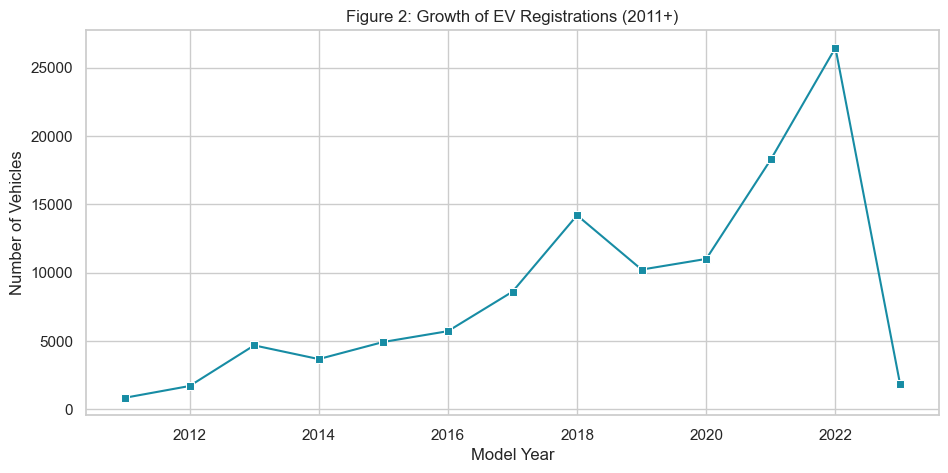

In [8]:
# check adoption trend over the years
plt.figure(figsize=(11, 5))

# filtering for 2011 onwards
yearly_trend = ev_df[ev_df["Model Year"] >= 2011]['Model Year'].value_counts().sort_index()

sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker="s", color="#178ca4") 
plt.title('Figure 2: Growth of EV Registrations (2011+)')
plt.xlabel('Model Year')
plt.ylabel("Number of Vehicles")
plt.show()

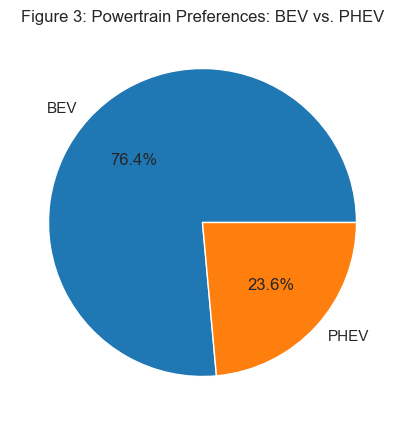

In [11]:
# bev vs phev proportion
plt.figure(figsize=(5, 5))

ev_counts = ev_df["Electric Vehicle Type"].value_counts()
my_colors = ['#1f77b4', '#ff7f0e'] 

plt.pie(ev_counts, labels=["BEV", "PHEV"], autopct="%1.1f%%", colors=my_colors)
plt.title('Figure 3: Powertrain Preferences: BEV vs. PHEV')
plt.show()

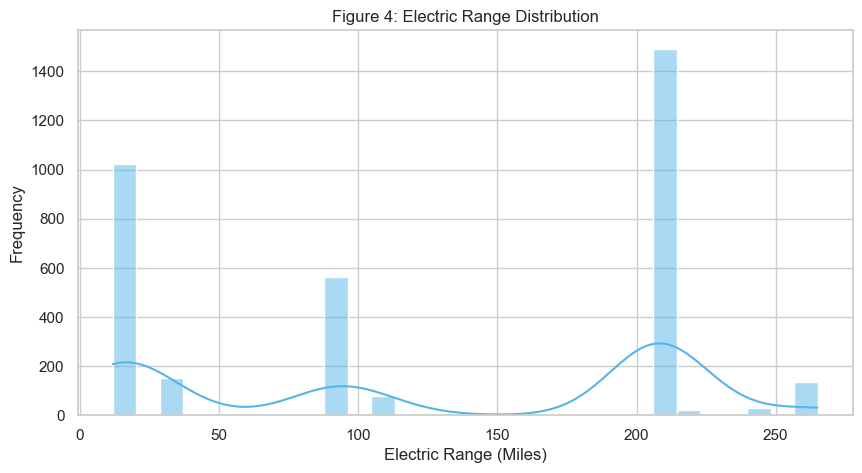

In [12]:
# checking the distribution of electric range
plt.figure(figsize=(10, 5))

sns.histplot(df_final["Electric Range"], bins=30, kde=True, color='#56B4E9')

plt.title('Figure 4: Electric Range Distribution')
plt.xlabel("Electric Range (Miles)")
plt.ylabel('Frequency')
plt.show()

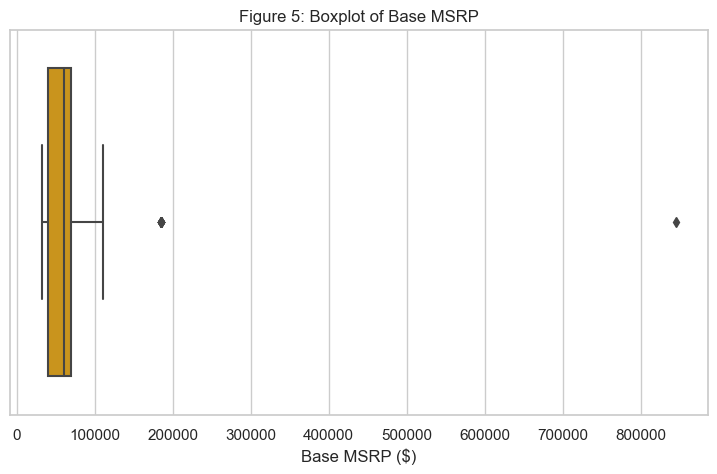

In [15]:
# boxplot to see the pricing spread and any remaining outliers
plt.figure(figsize=(9, 5))

sns.boxplot(x=df_final['Base MSRP'], color="#E69F00") 
plt.title("Figure 5: Boxplot of Base MSRP")
plt.xlabel("Base MSRP ($)")

# disable scientific notation for prices so it's readable
plt.ticklabel_format(style="plain", axis='x')
plt.show()

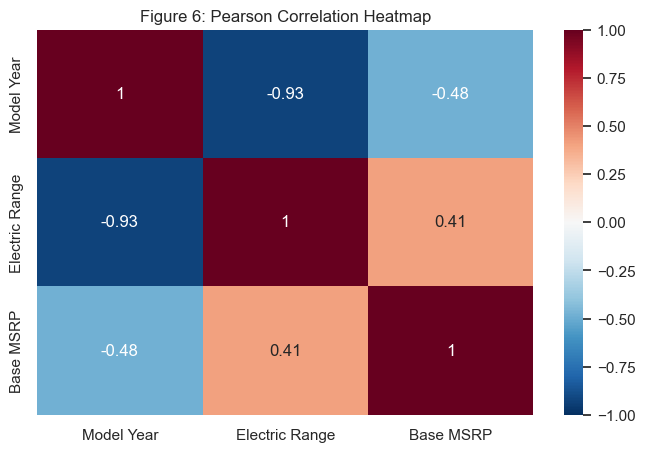

In [18]:
# correlation matrix for numeric features
plt.figure(figsize=(8, 5))

numeric_cols = df_final[["Model Year", 'Electric Range', "Base MSRP"]]
corr_matrix = numeric_cols.corr(method='pearson')

sns.heatmap(corr_matrix, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title('Figure 6: Pearson Correlation Heatmap')

plt.show()

# Machine Learning & Clustering (K-Means)

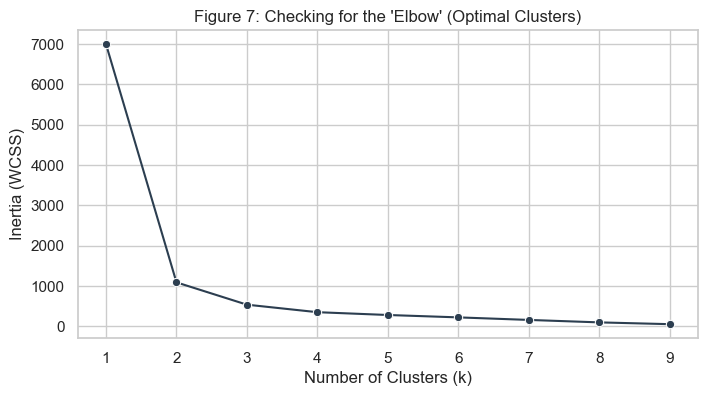

In [22]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# select features for clustering
X = df_final[['Model Year', 'Electric Range']].copy()

# standardize features 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertia = []
k_list = range(1, 10)

for k in k_list:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
   
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
sns.lineplot(x=list(k_list), y=inertia, marker="o", color="#2c3e50")

plt.title("Figure 7: Checking for the 'Elbow' (Optimal Clusters)")
plt.xlabel('Number of Clusters (k)')
plt.ylabel("Inertia (WCSS)")
plt.show()

cluster distribution:
 Cluster
Long Range      1681
Short Range     1145
Medium Range     672
Name: count, dtype: int64


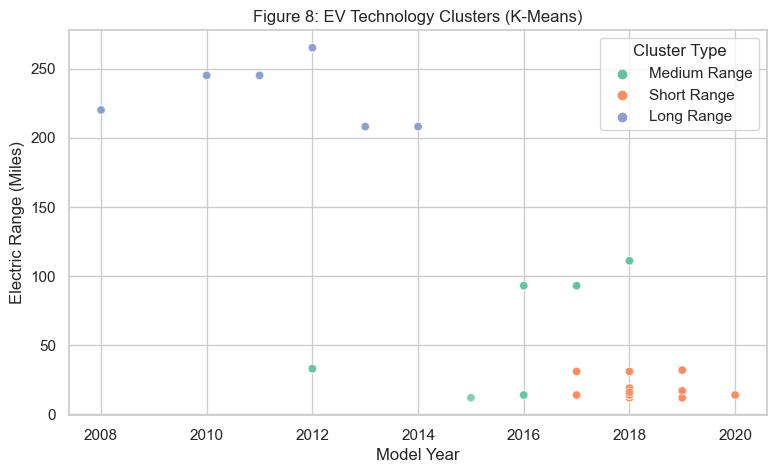

In [25]:
# select features for clustering
X = df_final[['Model Year', 'Electric Range']].copy()

# scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# fit k-means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
X['Cluster_ID'] = kmeans.fit_predict(X_scaled)

# sort clusters by mean electric range to name them logically
cluster_means = X.groupby('Cluster_ID')['Electric Range'].mean().sort_values()

# assign clear names based on their range
cluster_labels = {
    cluster_means.index[0]: 'Short Range',
    cluster_means.index[1]: 'Medium Range',
    cluster_means.index[2]: 'Long Range'
}

X['Cluster'] = X['Cluster_ID'].map(cluster_labels)

# check cluster distribution
print("cluster distribution:\n", X['Cluster'].value_counts())

# scatter plot with named clusters
plt.figure(figsize=(9, 5))
sns.scatterplot(data=X, x='Model Year', y='Electric Range', hue='Cluster', palette='Set2', alpha=0.8)

plt.title('Figure 8: EV Technology Clusters (K-Means)')
plt.xlabel('Model Year')
plt.ylabel('Electric Range (Miles)')
plt.legend(title='Cluster Type')
plt.show()

priced vehicles: 3498


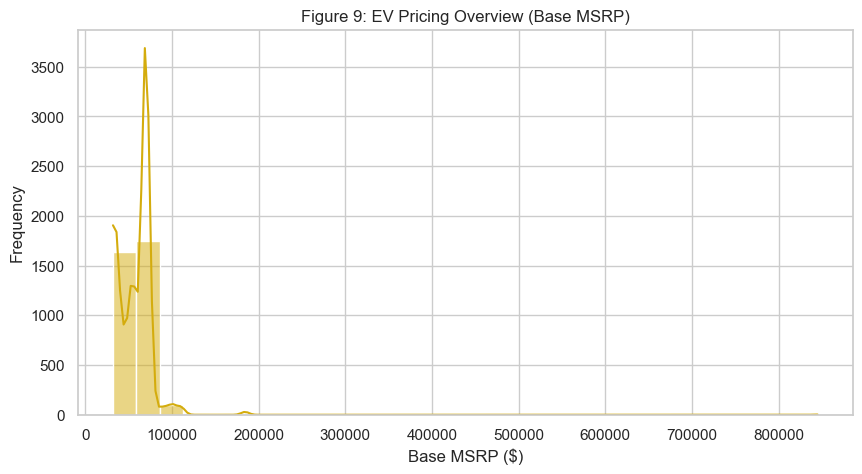

In [26]:
# filter 0 msrp
valid_price_df = ev_df[ev_df["Base MSRP"] > 0].copy()
print(f"priced vehicles: {len(valid_price_df)}")

plt.figure(figsize=(10, 5))

# price dist
sns.histplot(valid_price_df['Base MSRP'], bins=30, kde=True, color="#d4ac0d")
    
plt.title("Figure 9: EV Pricing Overview (Base MSRP)")
plt.xlabel('Base MSRP ($)')
plt.ylabel("Frequency")
    
# disable sci notation
plt.ticklabel_format(style="plain", axis='x')
plt.show()